# A balance sheet in 19 time bands: the repricing gap, the duration gap and a first EVE

**Question:** a bank with a 211.8 billion dollar balance sheet is placed in the 19 standard time bands; how much does a 100 basis point rise in rates cost it by the textbook repricing gap, the duration gap and a first economic value of equity, and how much of that cost rests on one assumption about how long the non-maturity deposits stay?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 to 04 of topic 01 (the engine, a `TestResult`, policies)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- place the cash flows of a balance sheet in the 19 standard time bands and say why the bands exist;
- read a repricing gap and the first-order effect on net interest income (NII) of a rate shift, and say what it leaves out;
- read a duration gap and the first-order effect on the value of equity, and say what it leaves out;
- discount the net cash flows into an economic value of equity (EVE) and explain why EVE is a present-value measure, not an accounting one;
- see how one assumption, the treatment of the non-maturity deposits, moves all three measures at once.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is the valuation date 2022-06-30 (2022-Q2) of case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, as Contraste commits it. Two sources feed it, both in the licence class `mirror-allowed` (`conventions/third-party-datasets.md`):

- the **FDIC call reports** of the bank (FDIC BankFind financials, https://api.fdic.gov/banks/financials, public domain), which give the balance sheet by repricing band;
- the **US Treasury daily par yield curve** (https://home.treasury.gov/resource-center/data-chart-center/interest-rates, public domain), which gives the rates that discount the flows.

The bank is **real in aggregate and synthetic in behaviour**: the totals are the bank's own, but the call report holds no deposit behaviour, no prepayment history and no profile finer than its bands, so every such assumption is stated by Contraste and labelled synthetic in the document. Money is in USD thousands, rates are decimals with continuous compounding, and a positive delta EVE or delta NII is a **loss**.

- **Files read:** `data/derived/C14/vd-2022-q2.json` (`outputs.balance_sheet`, `ladder`, `curve`, `scenarios`, `units`, `sign_convention`) and `data/derived/C14/models-svb-2021-2022.json` (the bilingual labels of the 19 bands).

The next cell loads both files and prints what the document says about itself: the bank, the units and the sign convention.

In [2]:
# Read the valuation date and the model document of case C14, and name the two treatments in this language
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
doc = json.loads((derived / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
out = doc["outputs"]
items = out["balance_sheet"]["items"]
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"behavioural": "behavioural", "contractual": "contractual"}
print(out["bank"]["name"], "|", out["valuation_date"], "|", out["currency"], "| USD thousands")
print(out["bank"]["notice"][LANG])
print(out["sign_convention"]["statement"][LANG])

Silicon Valley Bank | 2022-06-30 | USD | USD thousands
The call-report aggregates are the bank's own, read from the FDIC BankFind financials. Every behavioural assumption (deposit core share and maturity, prepayment, term-deposit redemption, the slotting of the report bands) is synthetic and stated in the document.
A positive delta EVE or delta NII is a loss; only losses are aggregated across currencies.


## Method

The method has five steps: (1) the 19 bands, (2) slotting cash flows into them, (3) the repricing gap and its first-order effect on NII, (4) the duration gap, (5) the EVE. Every number is a call to the engine; the notebook assembles the inputs from the committed document and draws what the engine returns.

### Step 1: the 19 time bands

The standardised framework of the Basel Committee slots every interest-rate-sensitive cash flow into 19 time bands, from overnight to over 20 years, and represents each band by its midpoint (BCBS, SRP31.96, Table 3, https://www.bis.org/basel_framework/chapter/SRP/31.htm). A band is an interval $(\text{lower}, \text{upper}]$: a flow at exactly one month is in the first band that ends at one month. The engine's `bucket_grid` returns the edges, the midpoints and the labels. The next cell prints seven of the nineteen bands.

In [3]:
# The engine's grid of 19 bands: the edges and the midpoint of each band, in years
grid = slotting.bucket_grid()
MID = grid.midpoints
print(f"{'band':>6s} {'lower (y)':>14s} {'upper (y)':>14s} {'midpoint (y)':>14s}")
for k in (0, 1, 2, 5, 9, 14, 18):
    print(f"{k + 1:6d} {grid.lower[k]:14.4f} {grid.upper[k]:14.4f} {MID[k]:14.4f}")
print("bands:", len(MID))

  band      lower (y)      upper (y)   midpoint (y)
     1         0.0000         0.0028         0.0028
     2         0.0028         0.0833         0.0417
     3         0.0833         0.2500         0.1667
     6         0.7500         1.0000         0.8750
    10         3.0000         4.0000         3.5000
    15         8.0000         9.0000         8.5000
    19        20.0000            inf        25.0000
bands: 19


### Step 2: slotting cash flows into the bands

`bucket_of` gives the band number of a time and `slot_cash_flows` adds a list of amounts at given times into the 19 bands (assets positive, liabilities negative); the sum of the result equals the sum of the amounts, so slotting moves money between bands and never creates or destroys it. The next cell slots a small example by hand-chosen times: a bullet loan of 1,000 maturing in 5 years, a deposit of 400 repricing in 2.3 years and a deposit of 300 repricing in exactly one month.

In [4]:
# Slot three flows by hand: the band of each time and the 19-band vector they make
times = np.array([5.0, 2.3, 1 / 12])
amounts = np.array([1000.0, -400.0, -300.0])
bands = [slotting.bucket_of(t, grid) for t in times]
slotted = slotting.slot_cash_flows(times, amounts, grid)
print("band of each flow:", bands)
print("non-zero bands:", {k + 1: float(v) for k, v in enumerate(slotted) if v != 0.0})
print("sum of the slotted flows:", float(slotted.sum()), "| sum of the amounts:", float(amounts.sum()))

band of each flow: [11, 9, 2]
non-zero bands: {2: -300.0, 9: -400.0, 11: 1000.0}
sum of the slotted flows: 300.0 | sum of the amounts: 300.0


### The committed balance sheet

The bank's balance sheet has 17 items (8 assets and 9 liabilities). The pipeline slotted each one into the 19 bands with the engine and committed the result twice: with the **behavioural** treatment of non-maturity deposits (the part the standard calls stable is spread over time, capped by the standard) and with the **contractual** treatment (every such deposit overnight). The next cell draws the items, assets on the left and liabilities on the right, and prints the two totals and the equity the books show.

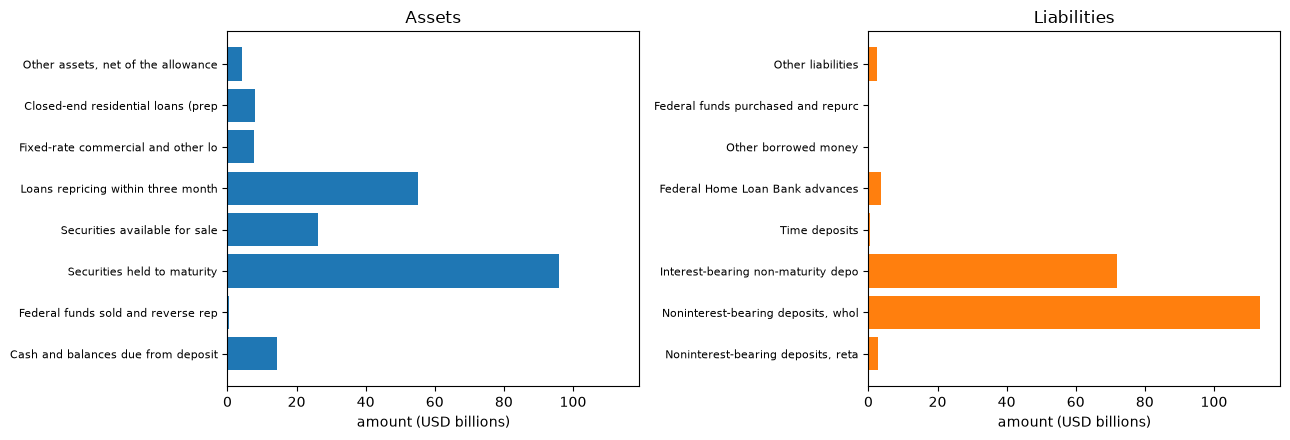

total assets: 211,824,000 | total liabilities: 196,438,000
equity in the books: 15,386,000


In [5]:
# Draw the 17 items, assets on the left and liabilities on the right, and print the totals of the books
side = {s: [it for it in items if it["side"] == s] for s in ("asset", "liability")}
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
panels = ((left, "asset", "tab:blue", "Assets"), (right, "liability", "tab:orange", "Liabilities"))
for ax, key, colour, title in panels:
    ax.barh([it["label"][LANG][:34] for it in side[key]], [it["amount"] / 1e6 for it in side[key]], color=colour)
    ax.set_title(title)
    ax.set_xlabel("amount (USD billions)")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()
assets = sum(it["amount"] for it in side["asset"])
liabilities = sum(it["amount"] for it in side["liability"])
print(f"total assets: {assets:,.0f} | total liabilities: {liabilities:,.0f}")
print(f"equity in the books: {assets - liabilities:,.0f}")

The two panels show where the money of the bank sits. On the asset side the securities held to maturity dwarf everything else, about 95.8 billion dollars of long, fixed-rate paper, with the loans repricing within three months and the available-for-sale securities behind; on the liability side the deposits are the large bars. The picture does not say when each item reprices, only how big it is: the timing is the job of the 19 bands, which the next step builds for the two treatments of the deposits. What follows from the totals is that the books show a small equity, a thin 7 percent of assets, which any measure of rate risk has to be read against.

### Step 3: the repricing gap and the first-order effect on NII

The 19-band vector of each item is in `cash_flows`. The next cell builds the vectors of the assets and of the liabilities under each treatment (liabilities are stored as negative amounts, and the gap functions take magnitudes, so the liability vector is the negative of the stored sum) and asks the engine for the repricing gap of each.

The repricing gap of band $k$ is the assets minus the liabilities that reprice in it, $G_k = RSA_k - RSL_k$, in money. For a parallel shift $\Delta r$ and a one-year horizon on a constant balance sheet, the textbook earnings-gap approximation of the change in NII is

$$\Delta NII \approx \sum_{t_k < 1} G_k \,\Delta r\, (1 - t_k)$$

where $t_k$ is the midpoint of band $k$ in years: a gap that reprices early earns the new rate for the rest of the year. It ignores basis risk, options and new business (source: dossier 05, D.1, and the earnings-gap literature; BCBS requires NII sensitivity under the two parallel scenarios for disclosure, d368). The engine's `delta_nii_gap` reports it **loss-positive**, so a positive gap earns more when rates rise and returns a negative number.

In [6]:
# Build the 19-band vectors of assets and liabilities under each treatment and take their repricing gaps
flows, gaps = {}, {}
for treatment in ("behavioural", "contractual"):
    vec = {"asset": np.zeros(19), "liability": np.zeros(19)}
    for it in items:
        for row in it["cash_flows"][treatment]:
            vec[it["side"]][row["bucket"] - 1] += row["amount"]
    flows[treatment] = (vec["asset"], -vec["liability"])
    gaps[treatment] = eve_nii.repricing_gap(*flows[treatment])
    top = int(np.argmax(np.abs(gaps[treatment])))
    print(f"{NAME[treatment]:12s} largest gap {gaps[treatment][top]:16,.0f} in band {top + 1}")

behavioural  largest gap      -76,433,446 in band 1
contractual  largest gap     -172,807,898 in band 1


The gaps are in hand. The next cell asks the engine for the first-order change in NII for +100 bp under each treatment, splits the behavioural one by band under one year, and draws the repricing ladder next to that split.

behavioural  delta NII for +100 bp (loss-positive):      199,057
contractual  delta NII for +100 bp (loss-positive):    1,199,488
sum of the contributions: 199057 | engine's delta NII: 199057


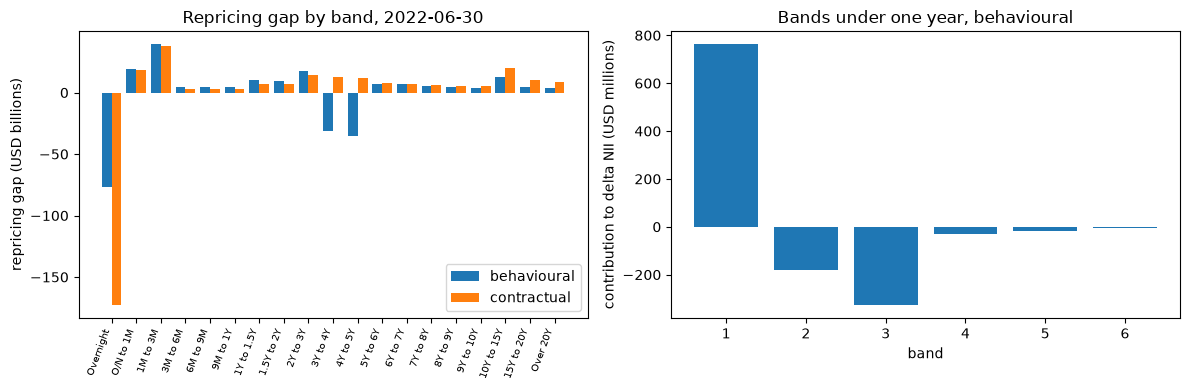

In [7]:
# The first-order change in NII for +100 bp under each treatment, and what each band under one year contributes
gap = gaps["behavioural"]
near = MID < 1.0
contribution = -gap[near] * 0.01 * (1.0 - MID[near])
for treatment in ("behavioural", "contractual"):
    d_nii = eve_nii.delta_nii_gap(gaps[treatment], MID, 100.0)
    print(f"{NAME[treatment]:12s} delta NII for +100 bp (loss-positive): {d_nii:12,.0f}")
engine_value = eve_nii.delta_nii_gap(gap, MID, 100.0)
print("sum of the contributions:", round(float(contribution.sum())), "| engine's delta NII:", round(engine_value))
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(19)
left.bar(x - 0.2, gaps["behavioural"] / 1e6, 0.4, label=NAME["behavioural"])
left.bar(x + 0.2, gaps["contractual"] / 1e6, 0.4, label=NAME["contractual"])
left.set_xticks(x)
names = [b["label"][LANG] for b in models["fit"]["buckets"]]
left.set_xticklabels(names, rotation=70, ha="right", fontsize=7)
left.set_ylabel("repricing gap (USD billions)")
left.set_title("Repricing gap by band, 2022-06-30")
left.legend()
right.bar(np.arange(1, near.sum() + 1), contribution / 1e3)
right.set_xlabel("band")
right.set_ylabel("contribution to delta NII (USD millions)")
right.set_title("Bands under one year, behavioural")
fig.tight_layout()
plt.show()

The left panel is the repricing ladder. Under the behavioural treatment the overnight band holds a large negative gap, the deposits that reprice at once, and the bands from one month to a year hold positive gaps of assets that reprice soon; under the contractual treatment every non-maturity deposit is overnight, so the overnight gap is more than twice as negative. The right panel splits the behavioural delta NII into its bands under one year: the overnight band is a loss because its weight $1 - t_k$ is almost one, and the five other bands give back gains that net it down to the small number printed above. What follows is that the net is a difference of larger numbers, so a validator reads the whole ladder and not only its sum. The picture does not show options, basis risk or new business, which the approximation leaves out.

### Step 4: the duration gap and the first-order effect on equity

The duration gap compares how long the assets and the liabilities take, weighted by value, to repay in present-value terms. With the present value of the assets $A$ and of the liabilities $L$, and their value-weighted durations $D_A$ and $D_L$,

$$DGAP = D_A - \frac{L}{A}\, D_L, \qquad \Delta E \approx -DGAP \cdot A \cdot \Delta y$$

(source: dossier 05, D.2: a textbook first-order approximation with no single primary source). With continuous compounding the modified duration equals the Macaulay duration, the value-weighted average time. A positive gap means the assets are longer than the liabilities, so a rate rise lowers equity. The engine's `duration_gap` needs the flows, the zero rates at the midpoints and the midpoints; so first we need the rates.

#### The zero curve

The Treasury publishes **par yields** at 12 tenors; discounting needs **zero rates**. The engine's `bootstrap_zero_curve` turns the par yields into continuously compounded zero rates (semiannual bond-equivalent coupons, simple interest up to six months), and `zero_rates_at` interpolates them linearly in tenor, flat outside the grid, at the 19 midpoints. `discount_factors` turns those rates into $DF_k = \exp(-R_k t_k)$. The next cell does the three steps from the observed yields and draws them.

curve kind: par-yield | tenors: 12
missing tenor (years): [0.333333]
discount factors at bands 1, 10 and 19: [0.999964, 0.901054, 0.442993]


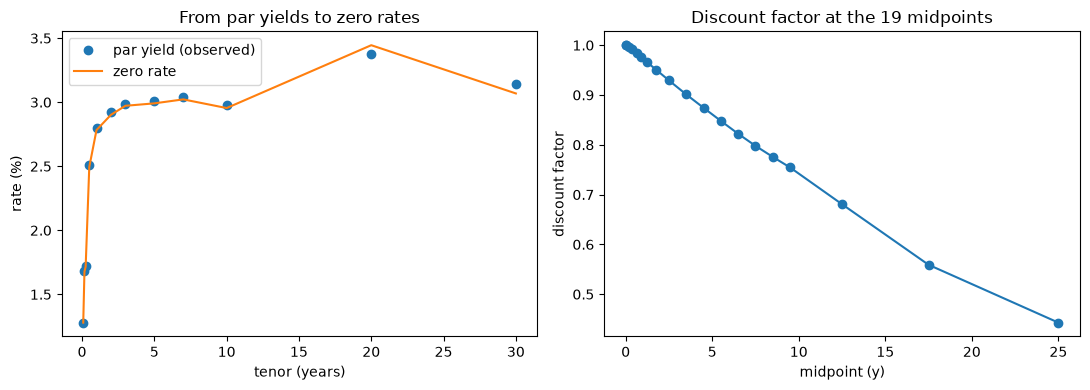

In [8]:
# Bootstrap the zero curve from the observed par yields, read it at the 19 midpoints and discount
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
par = np.array([p["observed_yield"] for p in points])
zero = curves.bootstrap_zero_curve(tenors, par, 2)
r0 = curves.zero_rates_at(tenors, zero, MID)
df = curves.discount_factors(r0, MID)
print("curve kind:", out["curve"]["observed_kind"], "| tenors:", len(tenors))
print("missing tenor (years):", out["curve"]["missing_tenors"])
print("discount factors at bands 1, 10 and 19:", [round(float(df[k]), 6) for k in (0, 9, 18)])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(tenors, par * 100, "o", label="par yield (observed)")
left.plot(tenors, zero * 100, label="zero rate")
left.set_xlabel("tenor (years)")
left.set_ylabel("rate (%)")
left.set_title("From par yields to zero rates")
left.legend()
right.plot(MID, df, marker="o")
right.set_xlabel("midpoint (y)")
right.set_ylabel("discount factor")
right.set_title("Discount factor at the 19 midpoints")
fig.tight_layout()
plt.show()

The left panel shows what the bootstrap changes: the zero rates sit a hair below the par yields at most tenors, because the same return written with continuous compounding is a slightly smaller number than the semiannual coupon convention of the par yield, and the gap opens at 20 years where the par yield of 3.38 percent becomes a zero rate of 3.45 percent. The curve is upward sloping from 1.3 percent at one month to 3.0 percent at three years, then flat. The 4-month tenor is missing from the Treasury series on that day and the curve is built from the 12 tenors that exist. The right panel is the consequence for the flows: a flow in the last band, 25 years out, is worth 44 cents on the dollar, and one in the first band is worth almost a full dollar. The picture shows one day only, 2022-06-30, when the curve was upward sloping and the discounting of the long assets was mild; the same book on another day has other discount factors.

#### The duration gap on the real book

Now the duration gap, for the behavioural and for the contractual treatment. The two treatments differ in the liabilities: with every non-maturity deposit overnight the liabilities have almost no duration, and the assets are much longer than the liabilities, so the gap is large. The next cell asks the engine for the gap and prints the present values and the durations.

In [9]:
# The duration gap of the book under each treatment, and the first-order change in equity for +100 bp
dgap = {}
for treatment, (a, l) in flows.items():
    dg = eve_nii.duration_gap(a, l, r0, MID)
    dgap[treatment] = dg
    print(NAME[treatment])
    print(f"  PV of assets {dg.asset_value:14,.0f} | PV of liabilities {dg.liability_value:14,.0f}")
    print(f"  duration of assets (y) {dg.asset_duration_years:7.4f}")
    print(f"  duration of liabilities (y) {dg.liability_duration_years:7.4f}")
    print(f"  duration gap (y) {dg.duration_gap_years:7.4f}")
    print(f"  equity change for +100 bp {dg.equity_change_100bp_up:14,.0f}")

behavioural
  PV of assets    192,515,579 | PV of liabilities    185,478,799
  duration of assets (y)  2.8407
  duration of liabilities (y)  1.8656
  duration gap (y)  1.0433
  equity change for +100 bp     -2,008,492
contractual
  PV of assets    185,093,900 | PV of liabilities    196,381,326
  duration of assets (y)  3.8215
  duration of liabilities (y)  0.0128
  duration gap (y)  3.8079
  equity change for +100 bp     -7,048,257


### Step 5: the economic value of equity

The EVE is the present value of the net cash flows: the assets minus the liabilities, each discounted at its zero rate. With net cash flows $CF_k$ (assets positive, liabilities negative) and the zero rates $R_k$ at the midpoints (BCBS SRP31.129; dossier 05, D.2):

$$DF_k = \exp(-R_k\, t_k), \qquad EVE = \sum_{k=1}^{19} CF_k \, DF_k$$

It is a **present-value** measure: it asks what the balance sheet is worth today if every flow is paid as slotted, not what the books say. That is why it can be far from the accounting equity, and why the treatment of the deposits, which the books carry at par, moves it so much. The next cell asks the engine for the EVE of each treatment with `eve` and draws it next to the equity of the books.

behavioural  EVE      7,036,780
contractual  EVE    -11,287,425
equity in the books: 15,386,000


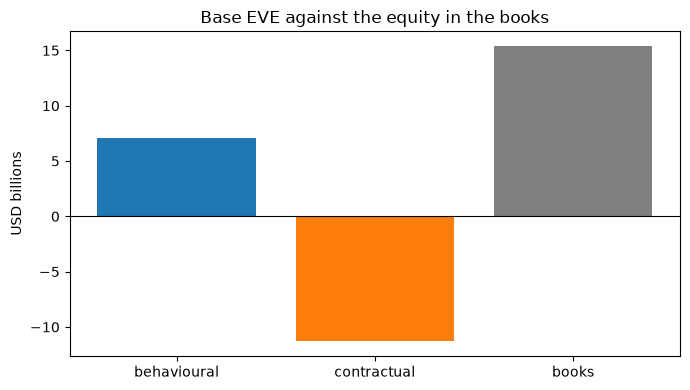

In [10]:
# The EVE of each treatment from the net flows and the zero curve, drawn next to the equity of the books
base = {t: eve_nii.eve(a - l, r0, MID) for t, (a, l) in flows.items()}
for treatment, value in base.items():
    print(f"{NAME[treatment]:12s} EVE {value:14,.0f}")
print(f"equity in the books: {assets - liabilities:,.0f}")
labels = [NAME["behavioural"], NAME["contractual"], "books"]
values = [base["behavioural"], base["contractual"], assets - liabilities]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, [v / 1e6 for v in values], color=["tab:blue", "tab:orange", "tab:grey"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("USD billions")
ax.set_title("Base EVE against the equity in the books")
fig.tight_layout()
plt.show()

The three bars are the same bank. The books show a positive equity of 15.4 billion dollars; the EVE with the behavioural treatment is less than half of that, and with every non-maturity deposit overnight the EVE is negative: on that reading the bank is worth less than its liabilities, 26.7 billion dollars below the books. The whole distance between the two EVE bars comes from one assumption, how long the non-maturity deposits stay, and no number in the call report decides it. What the picture does not show is whether the behavioural assumption is right: it is synthetic here, and notebook 03 takes it apart.

## Results

**Answer:** the textbook measures put the cost of a 100 basis point rise at a small number or a large one depending on one assumption. With the behavioural treatment the repricing gap gives a loss of NII of 199,057 (USD thousands), the duration gap is 1.0433 years and the first-order change in equity is -2,008,492, and the EVE is 7,036,780; with every non-maturity deposit overnight the NII loss is 1,199,488, the duration gap 3.8079 years, the equity change -7,048,257 and the EVE -11,287,425, against 15,386,000 of equity in the books.

- **Slotting.** The three-flow example lands in bands 11, 9 and 2, and its total, 300, is unchanged: slotting moves money between bands and never creates it. On the bank, 211,824,000 of assets and 196,438,000 of liabilities (USD thousands) sit in the books, and both treatments place all of it in the bands; the treatment changes where the liabilities are, never how much there is.
- **Repricing gap and NII.** The largest gap is -76,433,446 in the overnight band with the behavioural treatment and -172,807,898 with the contractual one. The overnight band contributes a loss of 762,194 and the five other bands under one year give back about 563,000, so the net 199,057 is the difference of larger numbers: a validator reads the whole ladder, not only its sum. The approximation holds the balance sheet constant, keeps one shift for every band and ignores options.
- **Duration gap.** The behavioural gap of 1.0433 years takes 13 percent of the books' equity for +100 bp; the contractual gap of 3.8079 years takes 46 percent. The two numbers are first order: they say which way and roughly how much, not how much exactly, and they cannot see the floors, the options or a non-parallel shock.
- **EVE.** The EVE is a present value of the flows as slotted, so it differs from the accounting equity, and the whole gap between the two EVEs comes from one assumption, how long the non-maturity deposits stay. Notebook 03 takes that assumption apart.
- **What the notebook does not show.** The standard's six shocks (notebook 02) and the behavioural assumptions behind the stable part of the deposits (notebook 03).

## Summary

- A balance sheet becomes 19 numbers per side: slotting moves each cash flow into the band of its repricing or maturity time and never changes the total.
- The repricing gap is assets minus liabilities by band; its first-order effect on NII keeps only the bands under one year, weighted by the time left in the year.
- The duration gap is the difference between the value-weighted durations of assets and liabilities, scaled by the leverage; it gives the first-order effect on equity.
- The EVE is a present value, and the treatment of non-maturity deposits moves it by more than the books' equity.
- Both approximations are first order and ignore options and basis risk; the next notebooks replace them with the standard's six shocks and with the behavioural layer.

**What to try next.** Change the +100 bp shift of `delta_nii_gap` to -100 bp and read the sign. Then continue with notebook 02, the six standard shocks.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31, Table 3 (the 19 time buckets) and SRP31.129 (the standardised EVE). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- FDIC, BankFind financials (call reports), public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research (IRRBB and ALM models), sections D.1 and D.2: the earnings-gap and duration-gap approximations.